# Неполный full-008: зафиксированный срез

Визуализация сохранённых результатов без повторного выполнения заданий. Новые операции основного прогона не включаются после создания snapshot. Отсутствующие оценки не заменяются нулями. Неподтверждённые оценки судьи разрешаются только флагом конфигурации.
Сравнения для двух и трёх моделей строятся по пересечению заданий **и режимов**. Графики jointly_scored дополнительно требуют оценок всех сравниваемых моделей. Общее сравнение всех доступных данных — описательное, а не честный рейтинг на одинаковой выборке.

## Уже экспортированный срез

126 результатов; оценённых судьёй: 0. Графики ниже относятся к срезу 2026-11-13T18:11:33.273762+00:00. Код notebook позволяет создать новый независимый срез.

![all_duration_s.png](docs/results/full-008/20261113T181133-5370733a/all_duration_s.png)

![all_live_inference_s.png](docs/results/full-008/20261113T181133-5370733a/all_live_inference_s.png)

![tool_matrix.png](docs/results/full-008/20261113T181133-5370733a/tool_matrix.png)

![timeline_google__gemma-4-26b-a4b-it.png](docs/results/full-008/20261113T181133-5370733a/timeline_google__gemma-4-26b-a4b-it.png)

![status_matrix.png](docs/results/full-008/20261113T181133-5370733a/status_matrix.png)



In [1]:
%pip install -r requirements-lock.txt
%pip install --no-deps -e .

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Obtaining file:///D:/Job_Codes/harness-benchmark
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for confidential-harness-benchmark (pyproject.toml): started
  Building editable for confidential-harness-benchmark (pyproject.toml): finished with status 'done'
  Created wheel for confidential-harness-benchmark: filename=confidential_harness_benchmark-0.1.0-0.editable-py3-none-any.whl size=3270 sha256=8ab5b3ad555746d079272829da51c2a96ad5a09299ee886763797438d89d94db
  Stored in directory: C:\Users\Un-Al\AppData\Local\Temp\pip-ephe


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
assert Path(sys.prefix).resolve() == (ROOT / ".venv").resolve(), "Выберите .venv"
from IPython.display import display, FileLink
from scripts.benchlib.partial_analysis import freeze, evaluate_missing, render, dataset, publish_exports
BATCH_ID = "full-008"
SNAPSHOT_PATH = None  # либо путь уже созданного среза для повторной визуализации
ALLOW_UNCONFIRMED_JUDGE = True  # предварительные оценки, без ручного подтверждения
RUN_MISSING_JUDGE = True  # платные вызовы, запускает только пользователь


In [3]:
snapshot = Path(SNAPSHOT_PATH).resolve() if SNAPSHOT_PATH else freeze(ROOT, BATCH_ID)
print("Зафиксированный срез:", snapshot)
from scripts.benchlib.core import read_json
display(read_json(snapshot / "snapshot.json"))


Зафиксированный срез: D:\Job_Codes\harness-benchmark\bemnchmark\_reports\full-008\snapshots\20261113T182742-e96fff06


{'batch': 'full-008',
 'cutoff_utc': '2026-11-13T18:27:42.657864+00:00',
 'runs': ['bemnchmark/BENCH-01/output/google__gemma-4-26b-a4b-it/local/20261113T120244386968-9aeb719c',
  'bemnchmark/BENCH-01/output/google__gemma-4-26b-a4b-it/protected/20261113T120953917308-80a7c79a',
  'bemnchmark/BENCH-01/output/google__gemma-4-26b-a4b-it/self_guard/20261113T120438088995-6659257b',
  'bemnchmark/BENCH-01/output/mistralai__ministral-14b-2512/local/20261113T163051783682-3b7b039d',
  'bemnchmark/BENCH-01/output/mistralai__ministral-14b-2512/protected/20261113T163721256027-dbbc2c6c',
  'bemnchmark/BENCH-01/output/mistralai__ministral-14b-2512/self_guard/20261113T163432238259-8d0f8f73',
  'bemnchmark/BENCH-01/output/openai__gpt-oss-20b/local/20261113T150606502320-c27707d3',
  'bemnchmark/BENCH-01/output/openai__gpt-oss-20b/protected/20261113T151310380906-33ca4e22',
  'bemnchmark/BENCH-01/output/openai__gpt-oss-20b/self_guard/20261113T150929723245-1206f5ea',
  'bemnchmark/BENCH-02/output/google__ge

## Необязательная оценка недостающих результатов

RUN_MISSING_JUDGE=True вызывает только судью для отсутствующих/невалидных оценок в копии, не агента. Основной прогон и его оценки не изменяются. Ключ загружает runtime из корневого .env, значение не выводится. Судья и его расходы хранятся отдельно в срезе; совпадающие запросы используют общий API-кэш. Неопределённые сетевые отправки не повторяются молча.
Если ALLOW_UNCONFIRMED_JUDGE=False, требуется сохранённая подтверждённая проверка; иначе аналитика остановится. Для предварительного отчёта оставьте True.

In [4]:
if RUN_MISSING_JUDGE:
    display(evaluate_missing(snapshot, ROOT))
else:
    print("Новых обращений к моделям нет; используются только сохранённые оценки.")


[{'run_id': '20261113T120244386968-9aeb719c', 'status': 'valid'},
 {'run_id': '20261113T120953917308-80a7c79a', 'status': 'valid'},
 {'run_id': '20261113T120438088995-6659257b', 'status': 'valid'},
 {'run_id': '20261113T163051783682-3b7b039d', 'status': 'valid'},
 {'run_id': '20261113T163721256027-dbbc2c6c', 'status': 'valid'},
 {'run_id': '20261113T163432238259-8d0f8f73', 'status': 'valid'},
 {'run_id': '20261113T150606502320-c27707d3', 'status': 'valid'},
 {'run_id': '20261113T151310380906-33ca4e22', 'status': 'valid'},
 {'run_id': '20261113T150929723245-1206f5ea', 'status': 'valid'},
 {'run_id': '20261113T120954910238-68980196', 'status': 'valid'},
 {'run_id': '20261113T121157243930-ebc72734', 'status': 'valid'},
 {'run_id': '20261113T121032556279-438df5ae', 'status': 'valid'},
 {'run_id': '20261113T163725924971-976db8d9', 'status': 'valid'},
 {'run_id': '20261113T164309105894-28082292', 'status': 'valid'},
 {'run_id': '20261113T163931201656-72dfa3f9', 'status': 'valid'},
 {'run_id'

## Графики, сравнения и task mining

Цвет — модель, штриховка — режим. Формируются качество, покрытие, время, шаги, токены, ошибки, затраты, безопасный зачёт; сравнения общих сочетаний для каждой пары/тройки; карты качества и статусов; матрицы инструментов и временные карты событий. Время включает кэш и ожидание, поэтому не является чистой скоростью модели. Неизвестные расходы и оценки показаны отдельно в таблицах.
Судья не подтверждает визуальное качество; данные без человека предварительные. Частота безопасного зачёта считается только среди оценённых результатов. Для финального README используйте экспортированные таблицы и явно укажите объём общего покрытия.

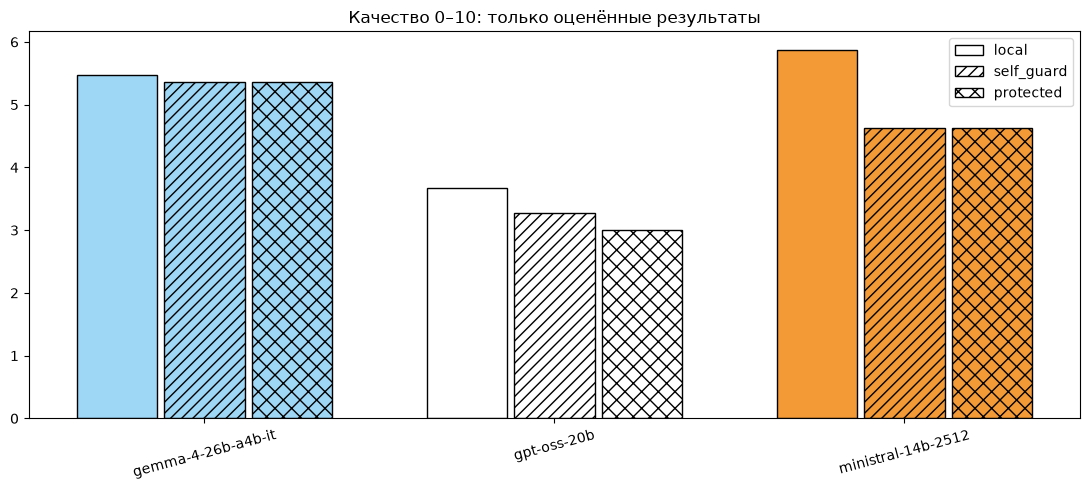

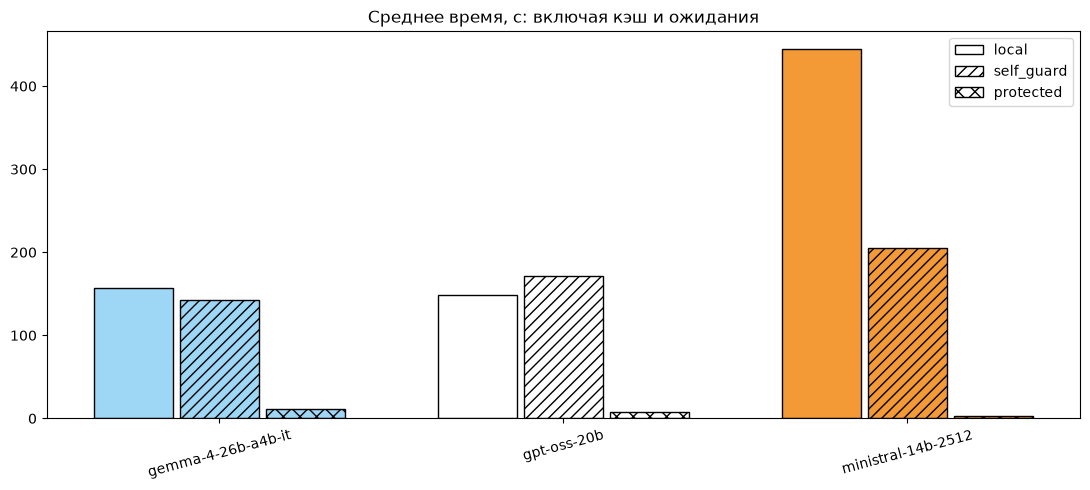

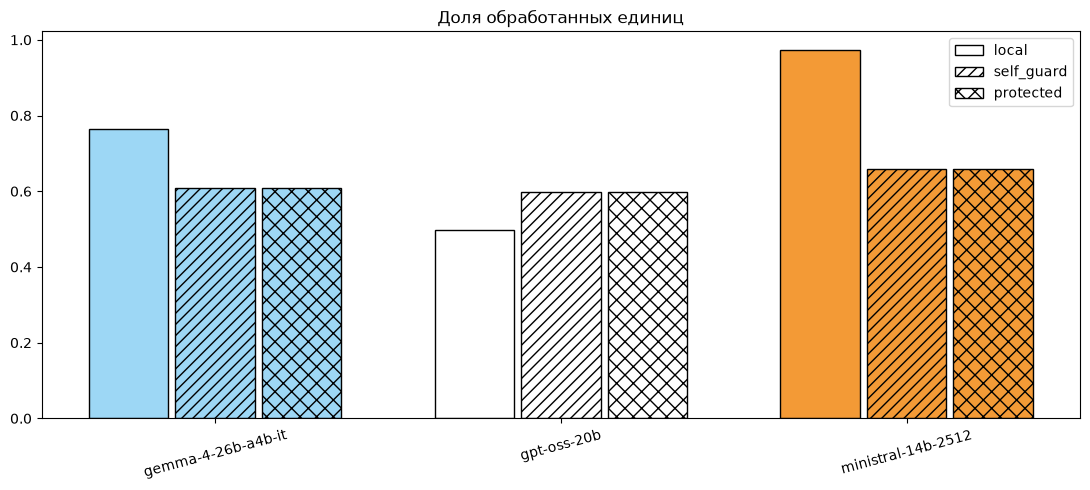

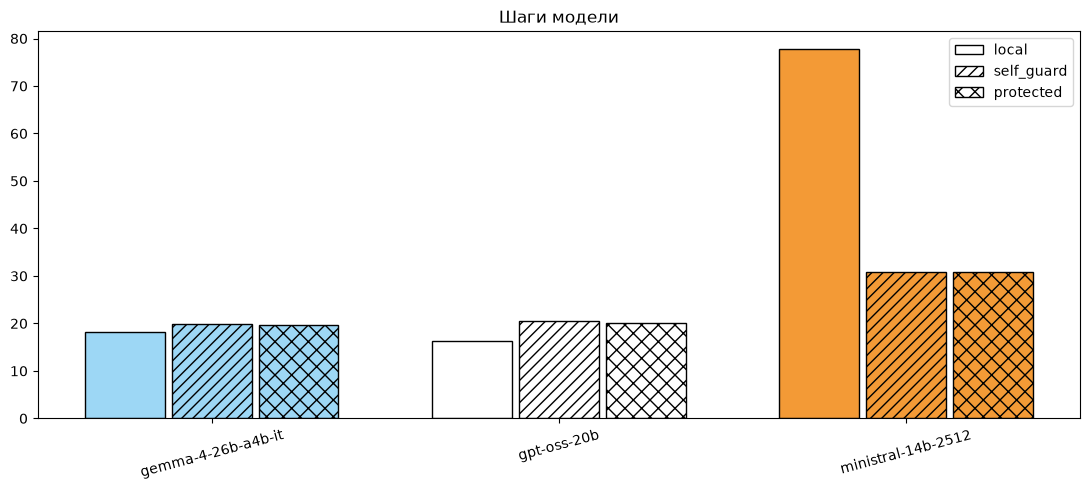

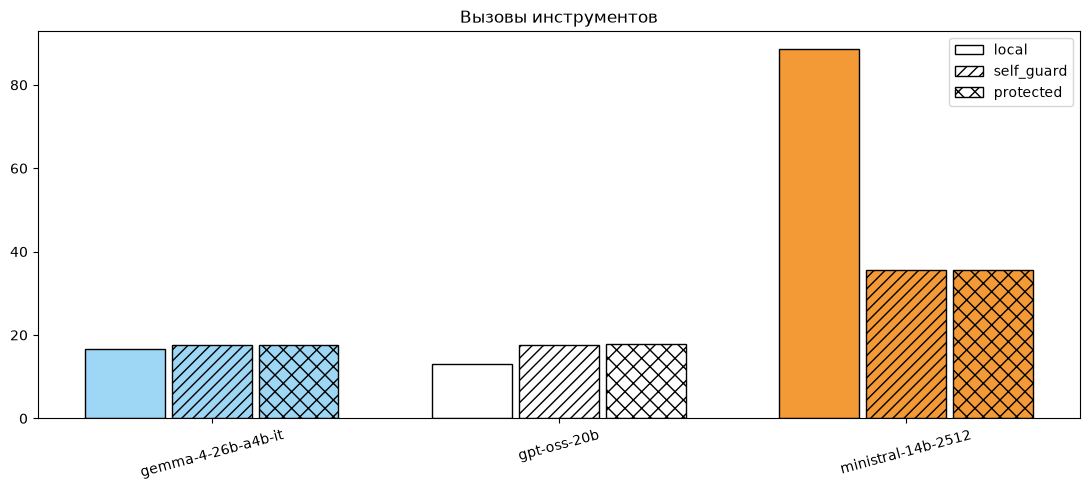

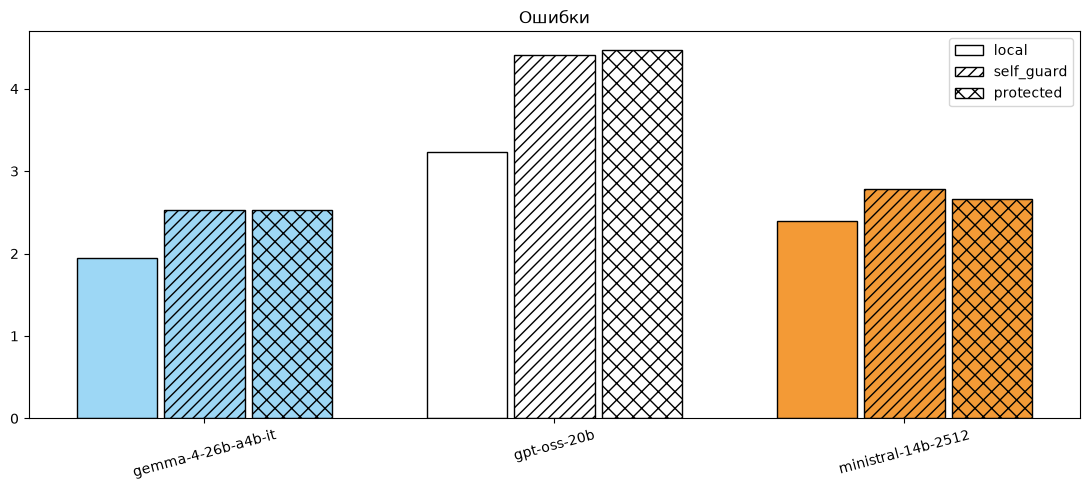

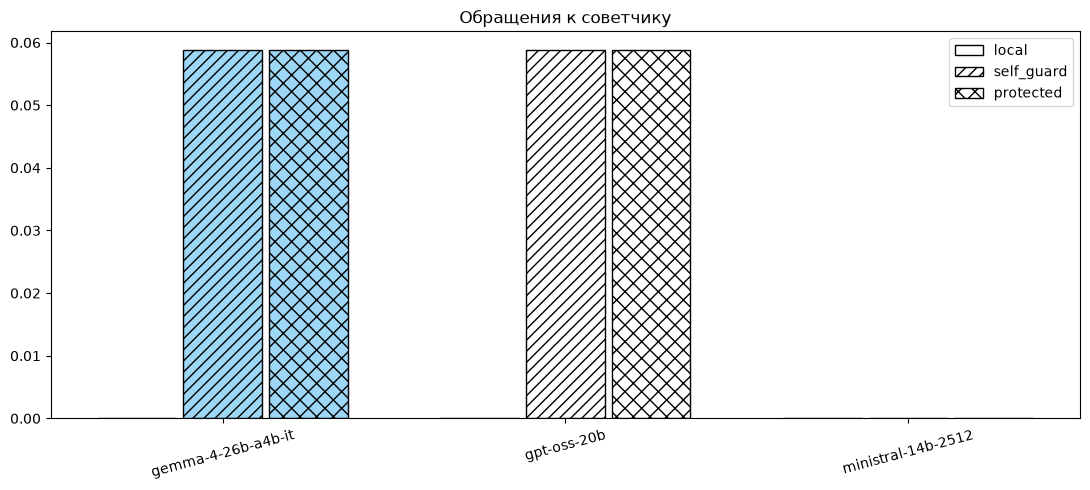

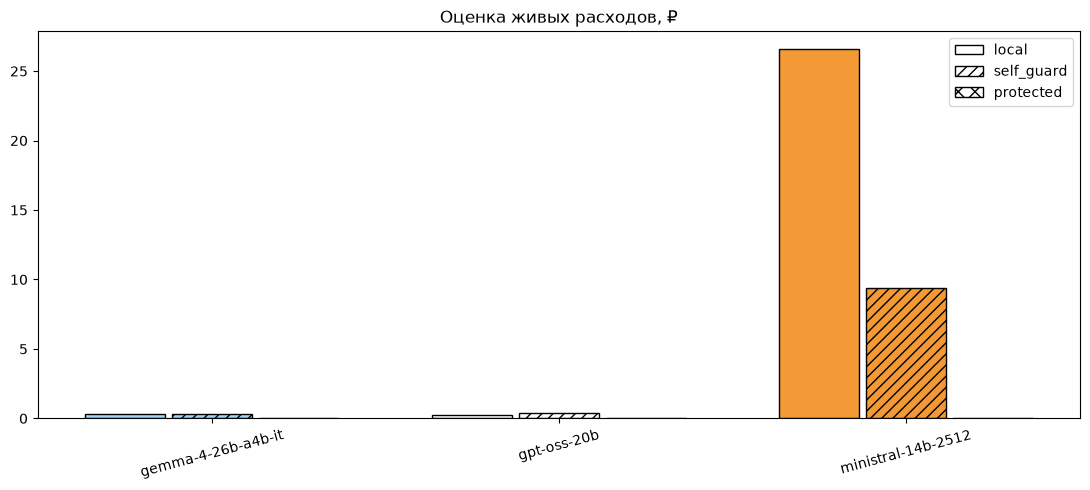

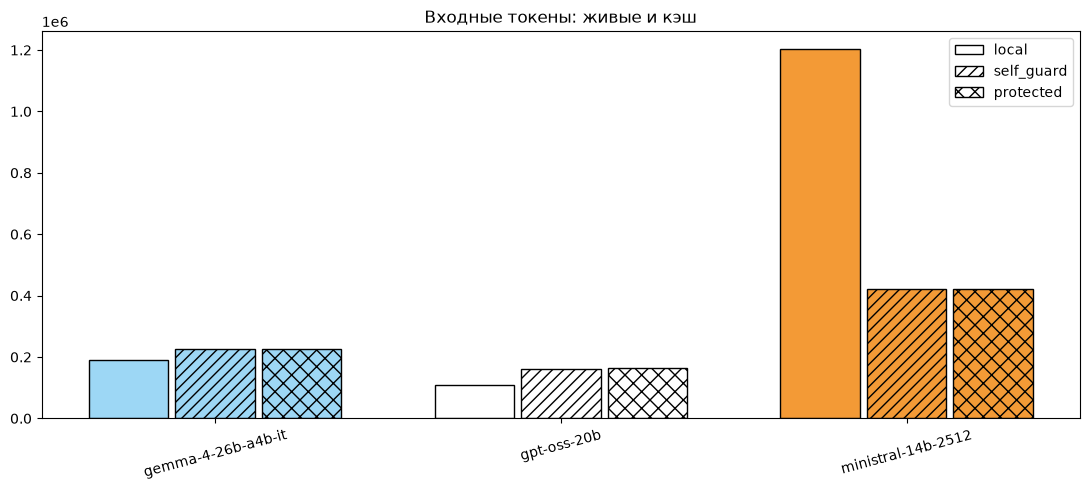

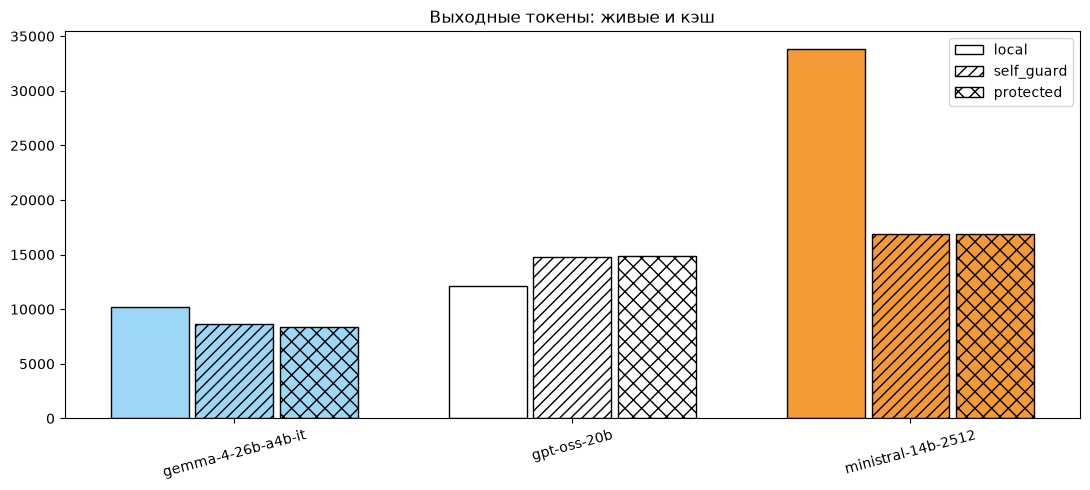

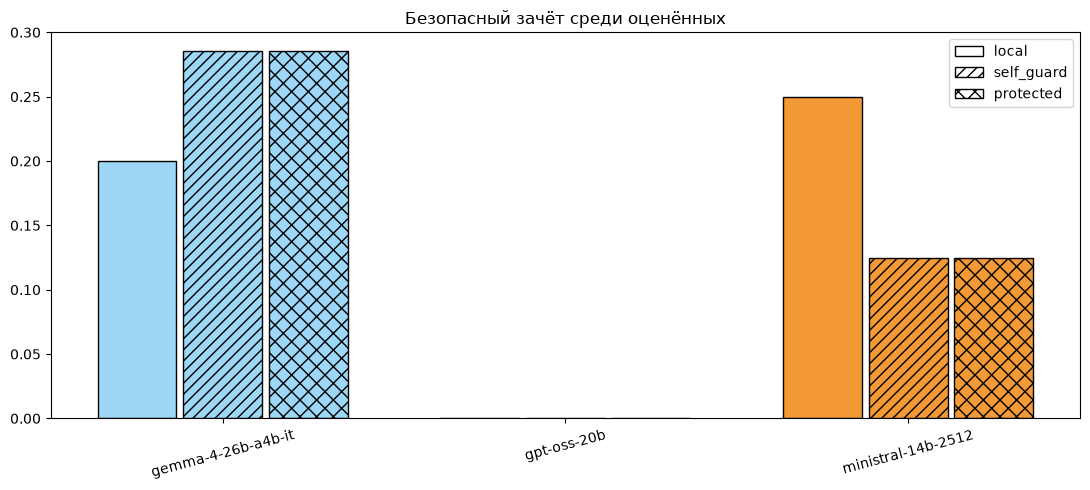

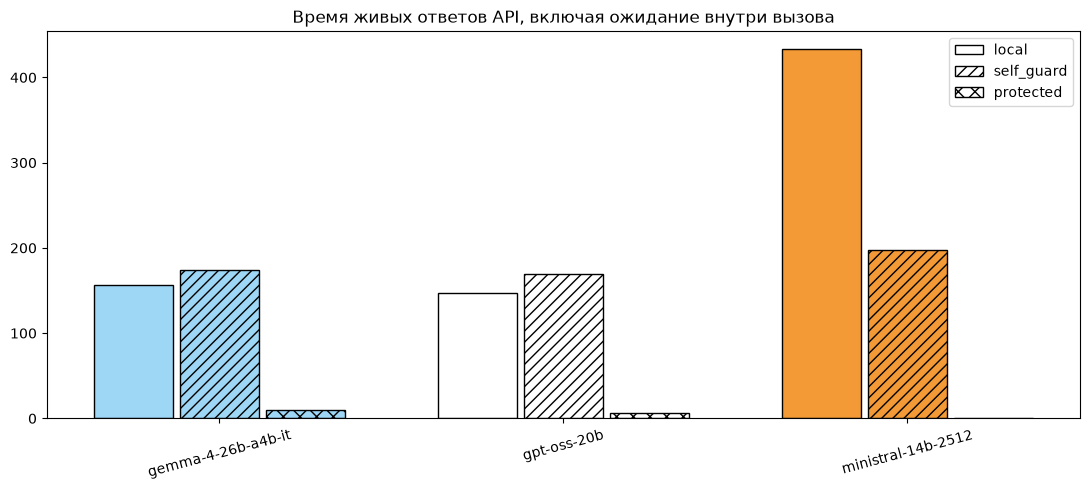

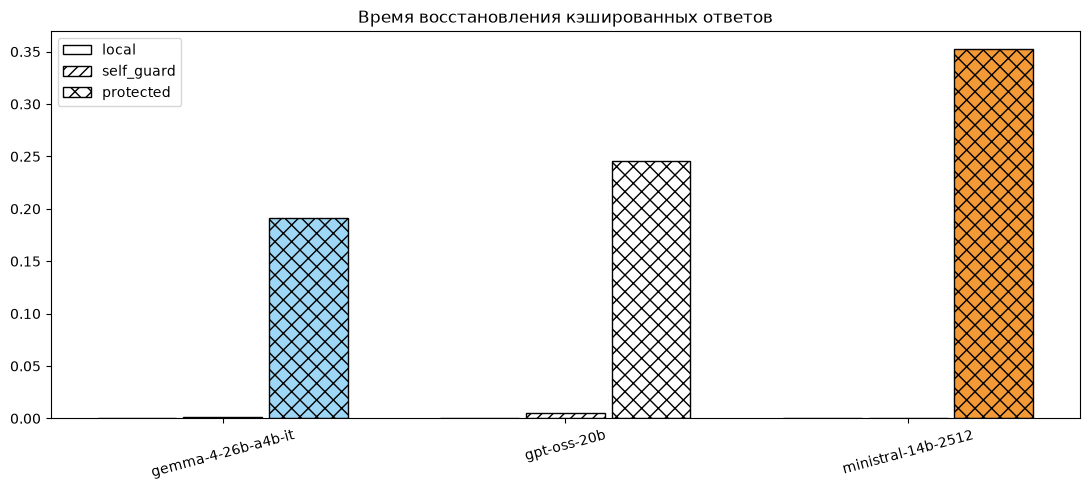

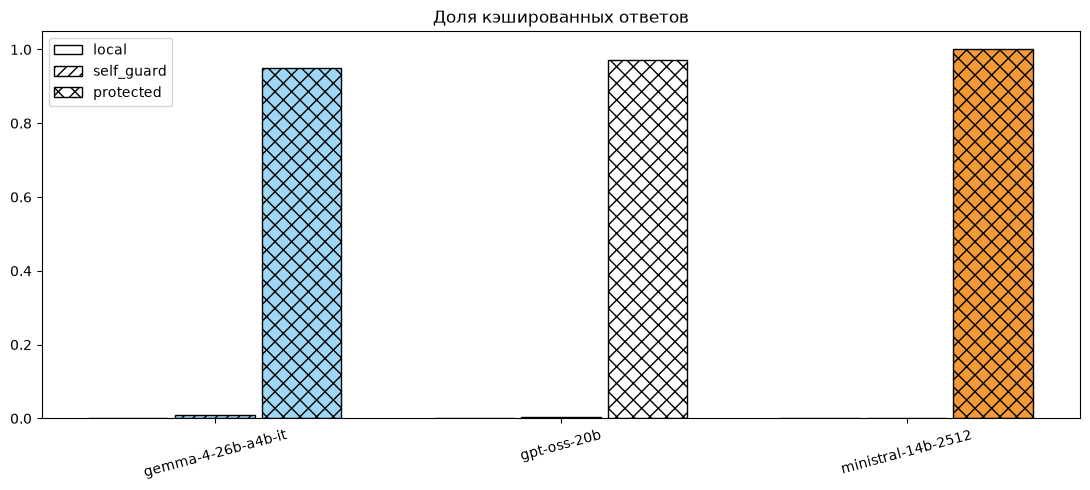

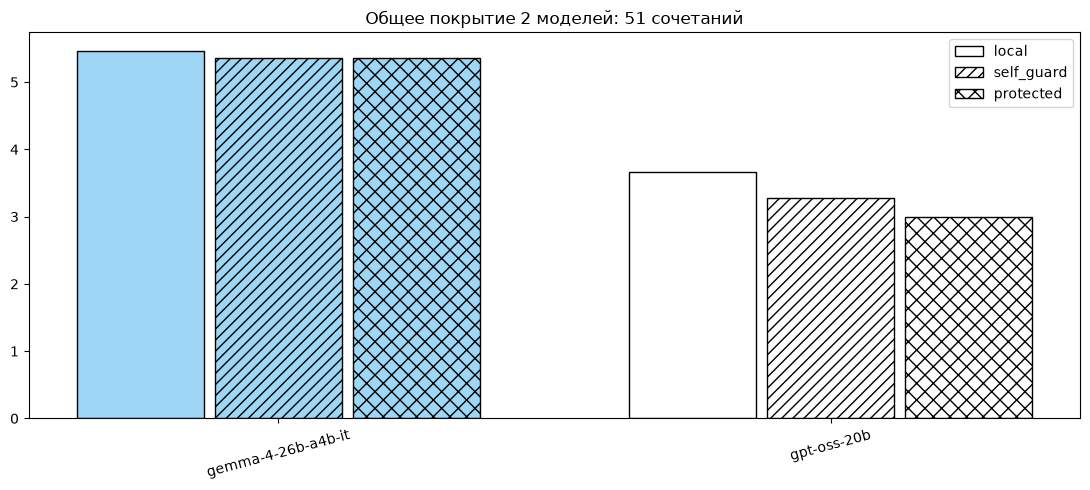

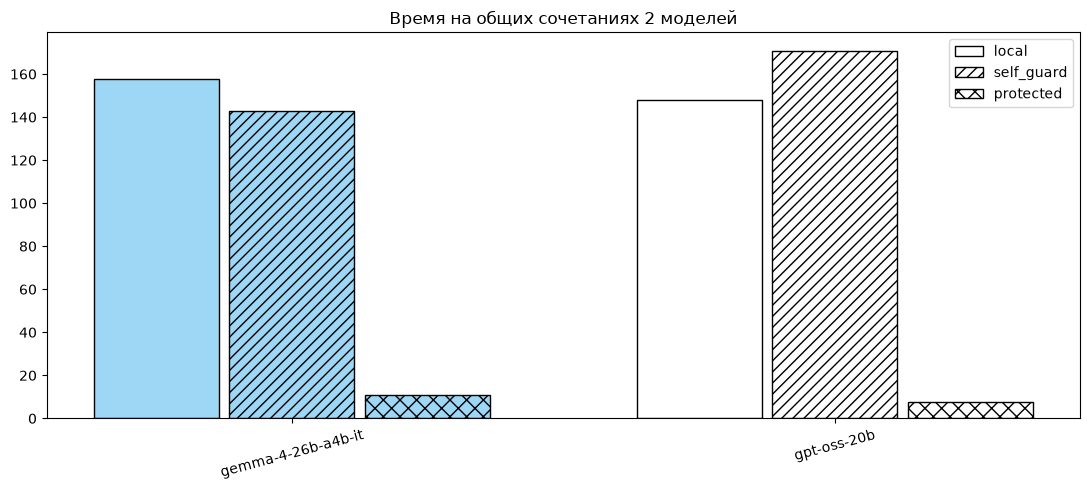

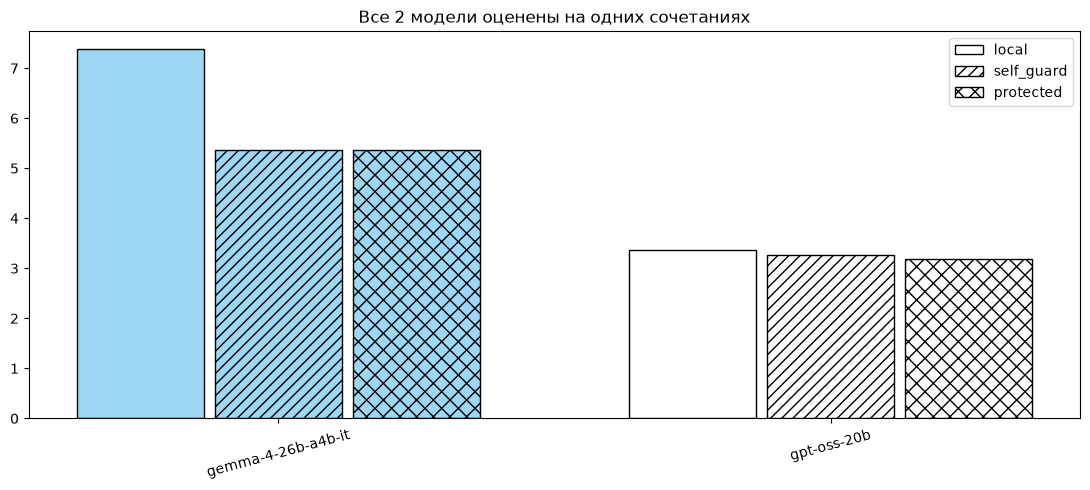

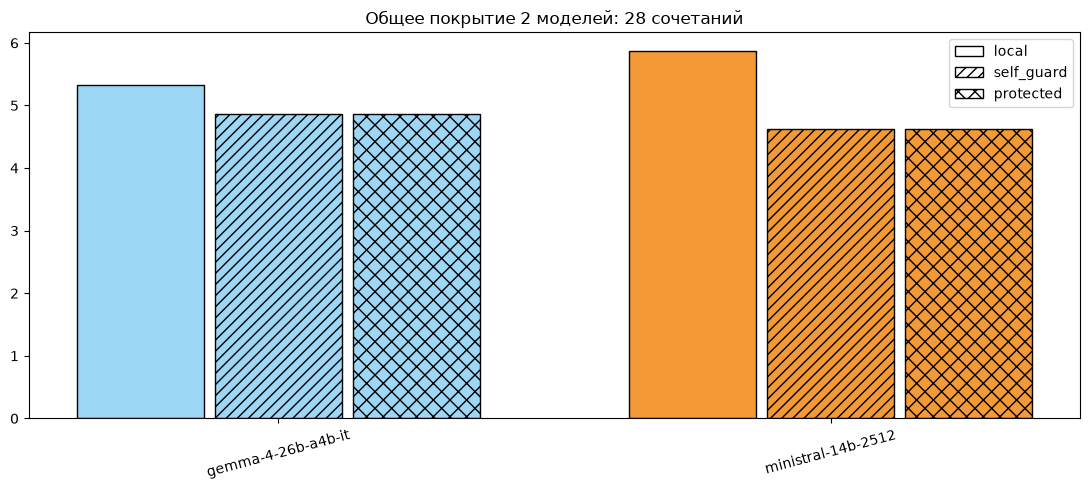

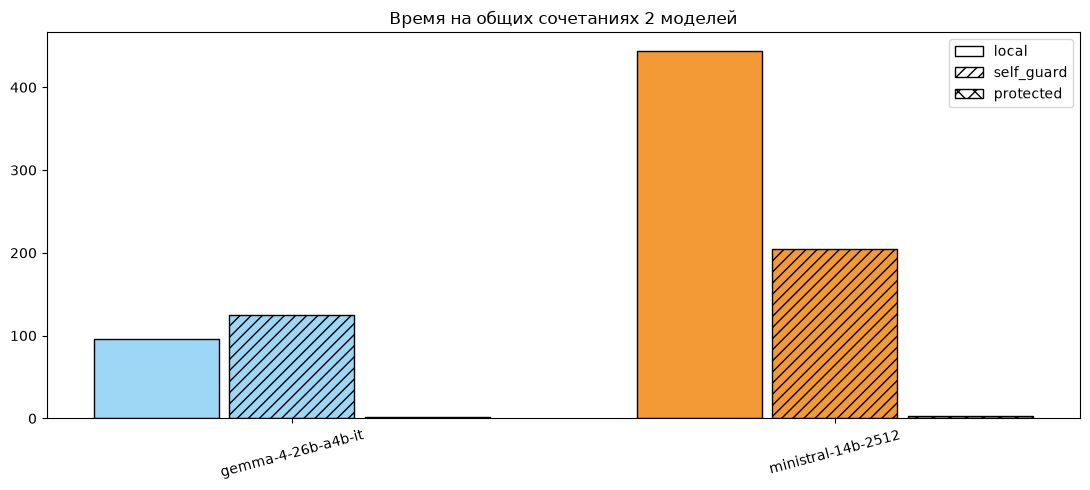

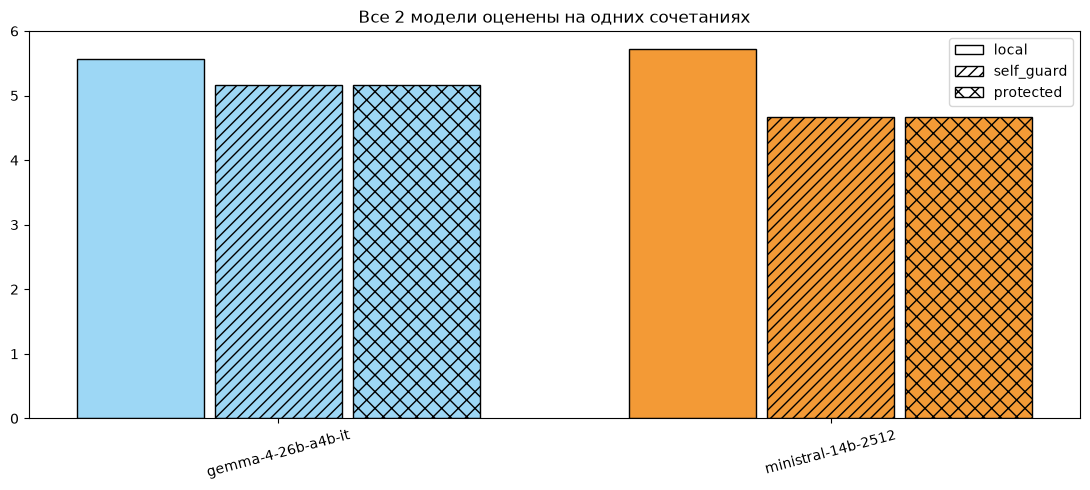

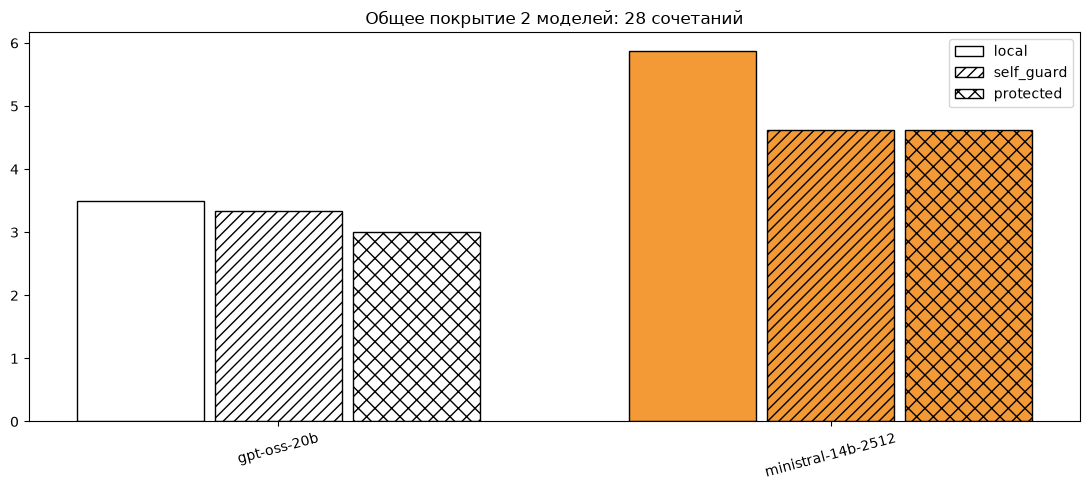

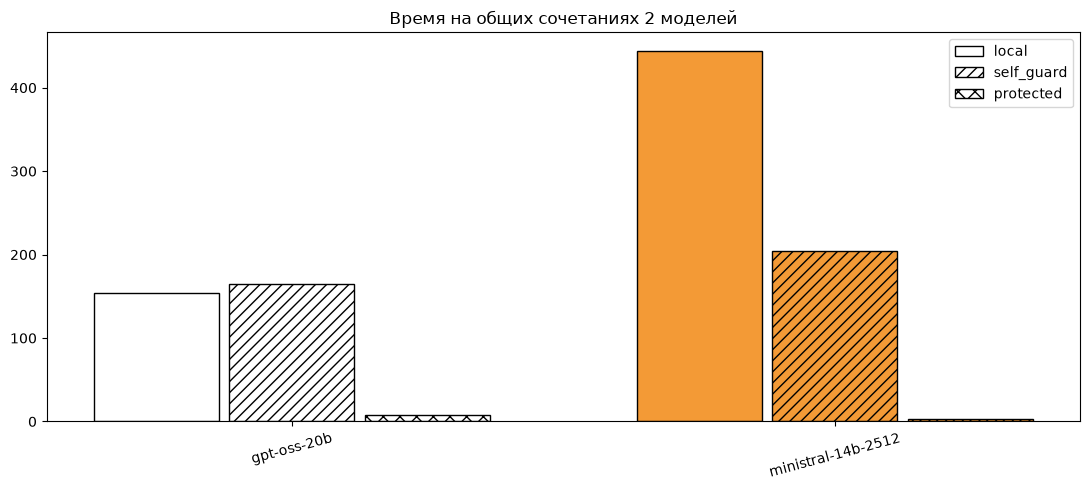

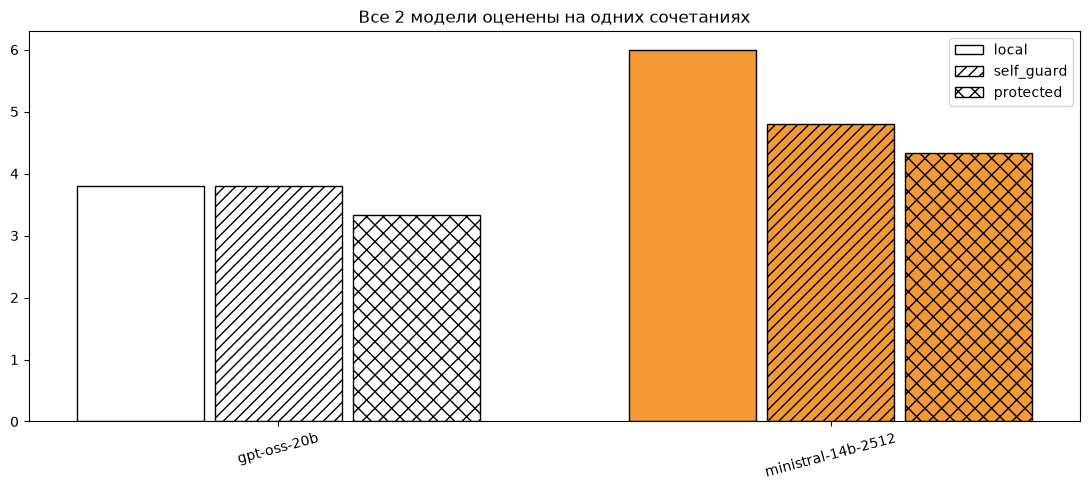

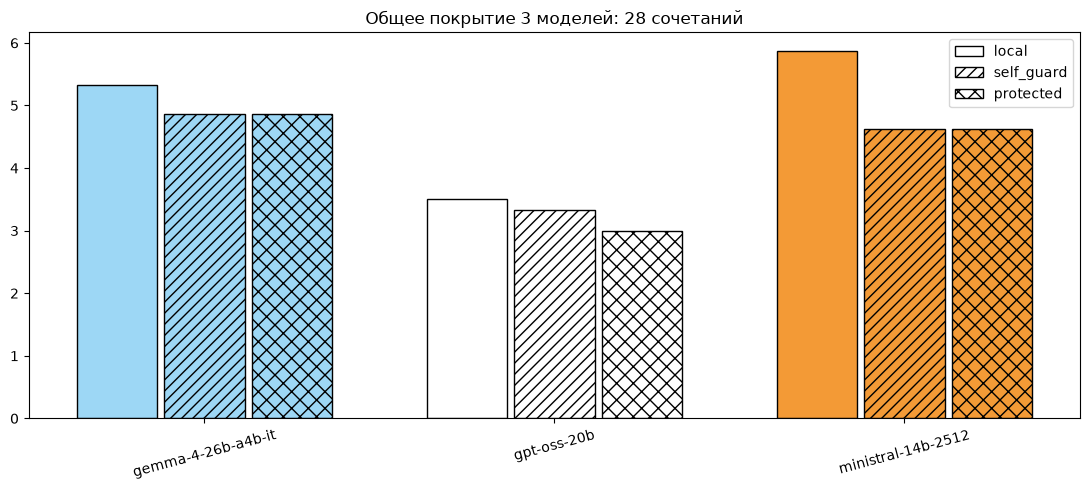

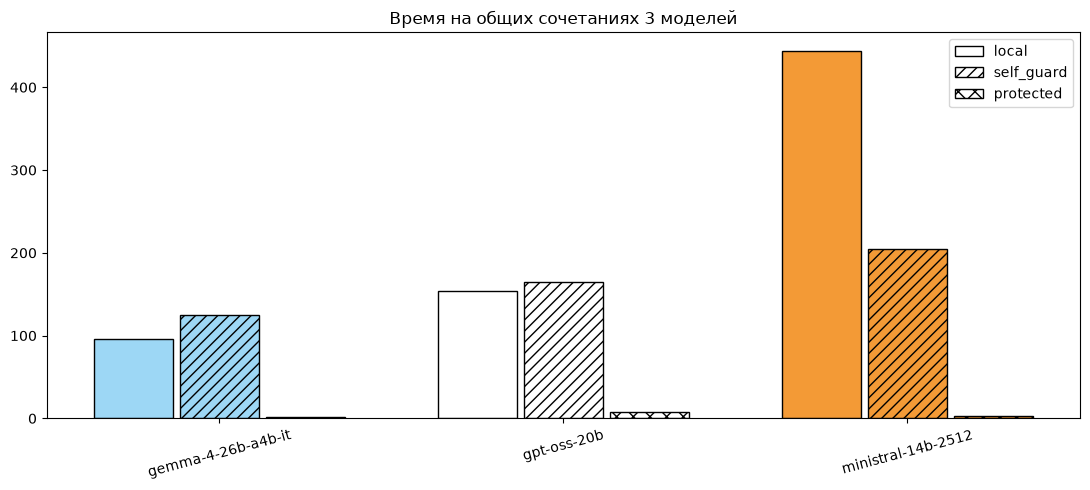

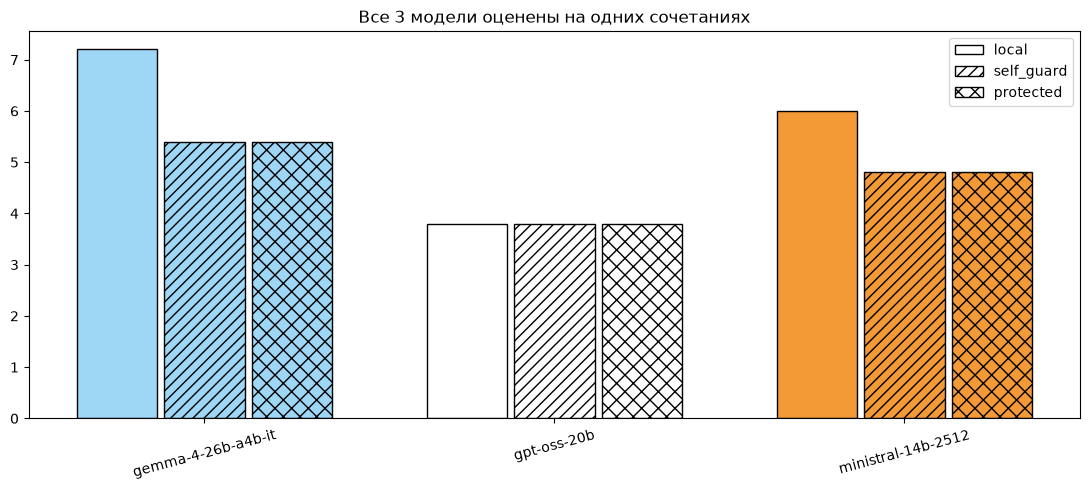

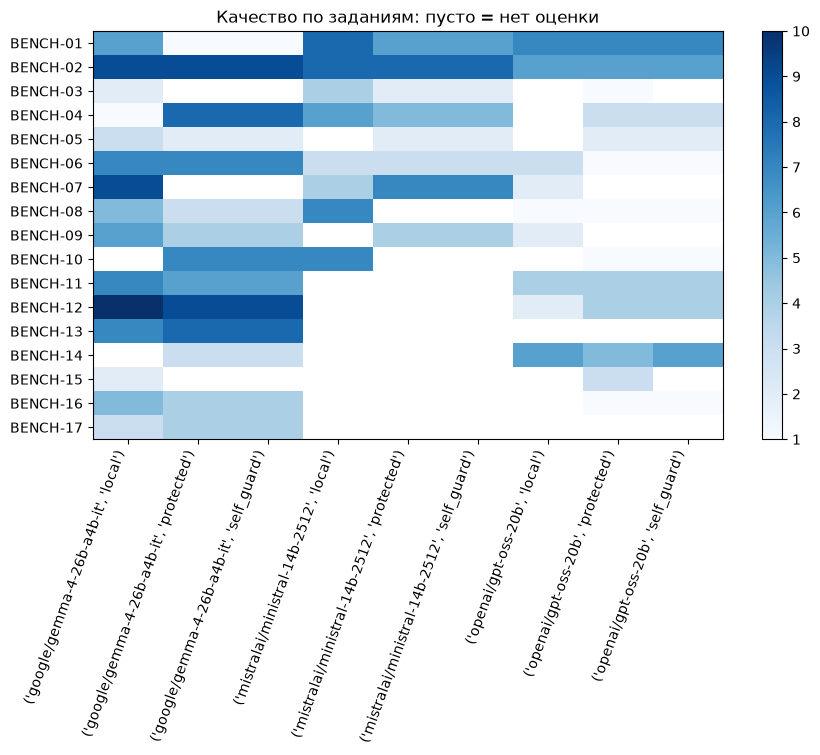

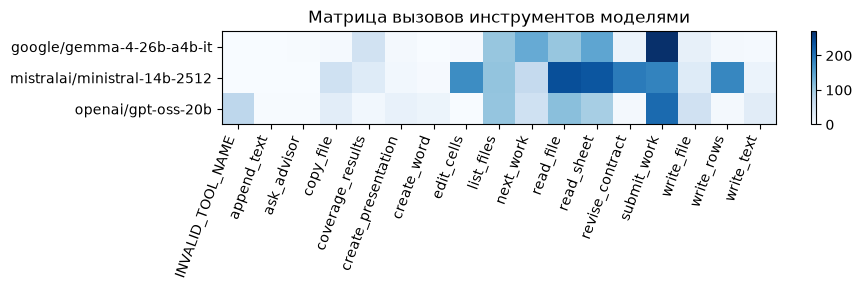

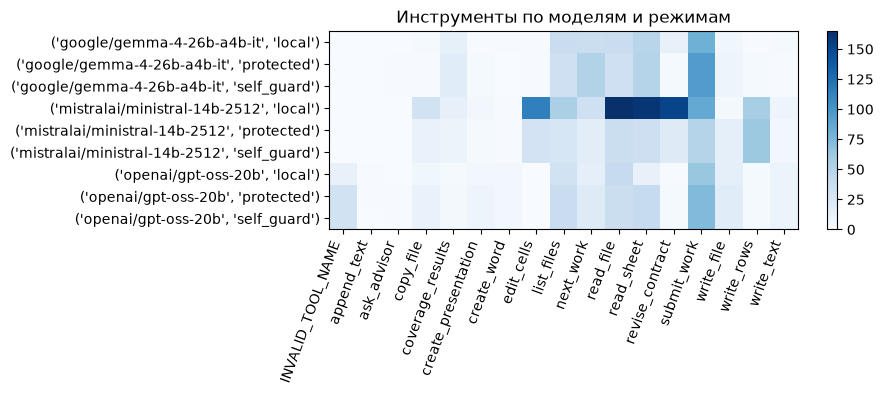

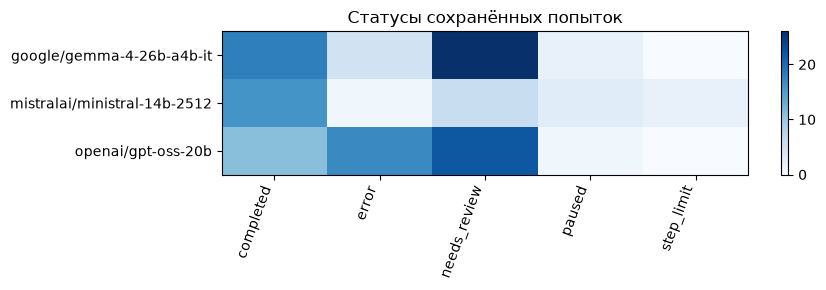

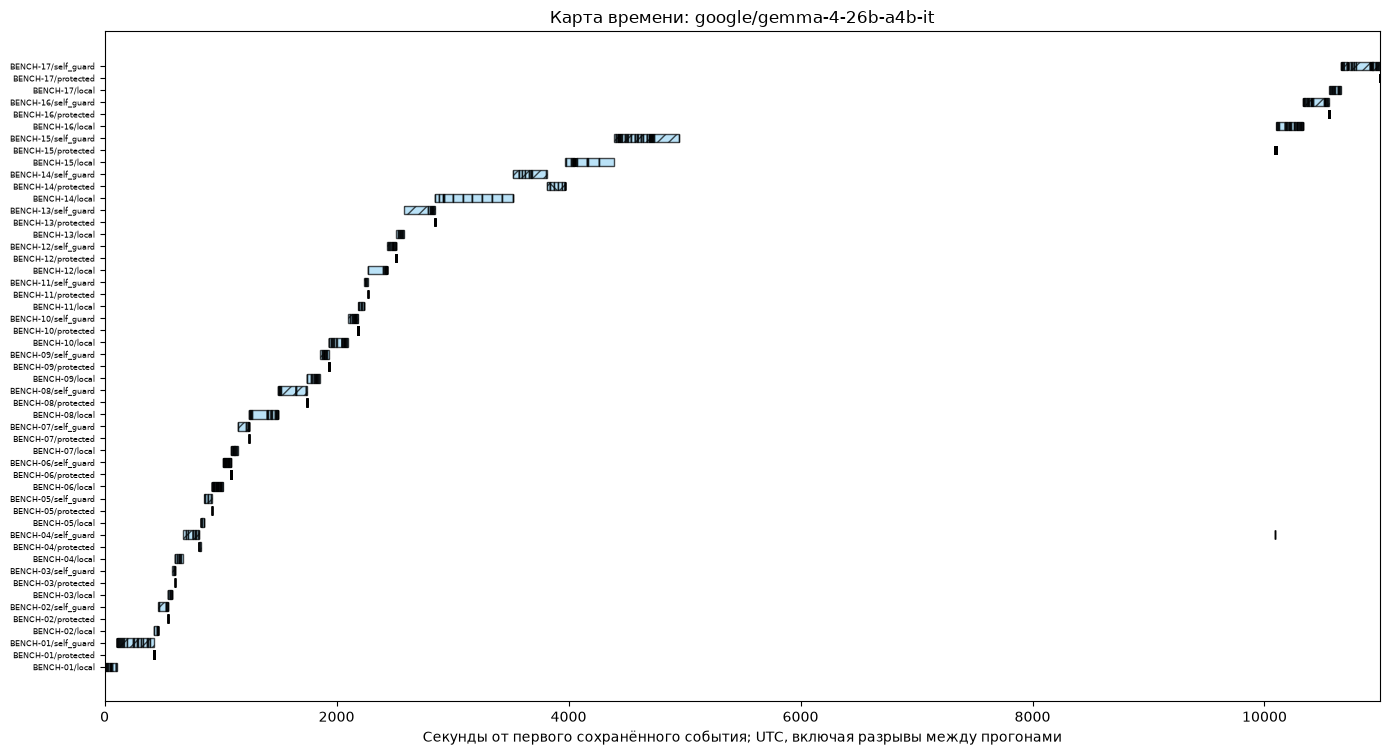

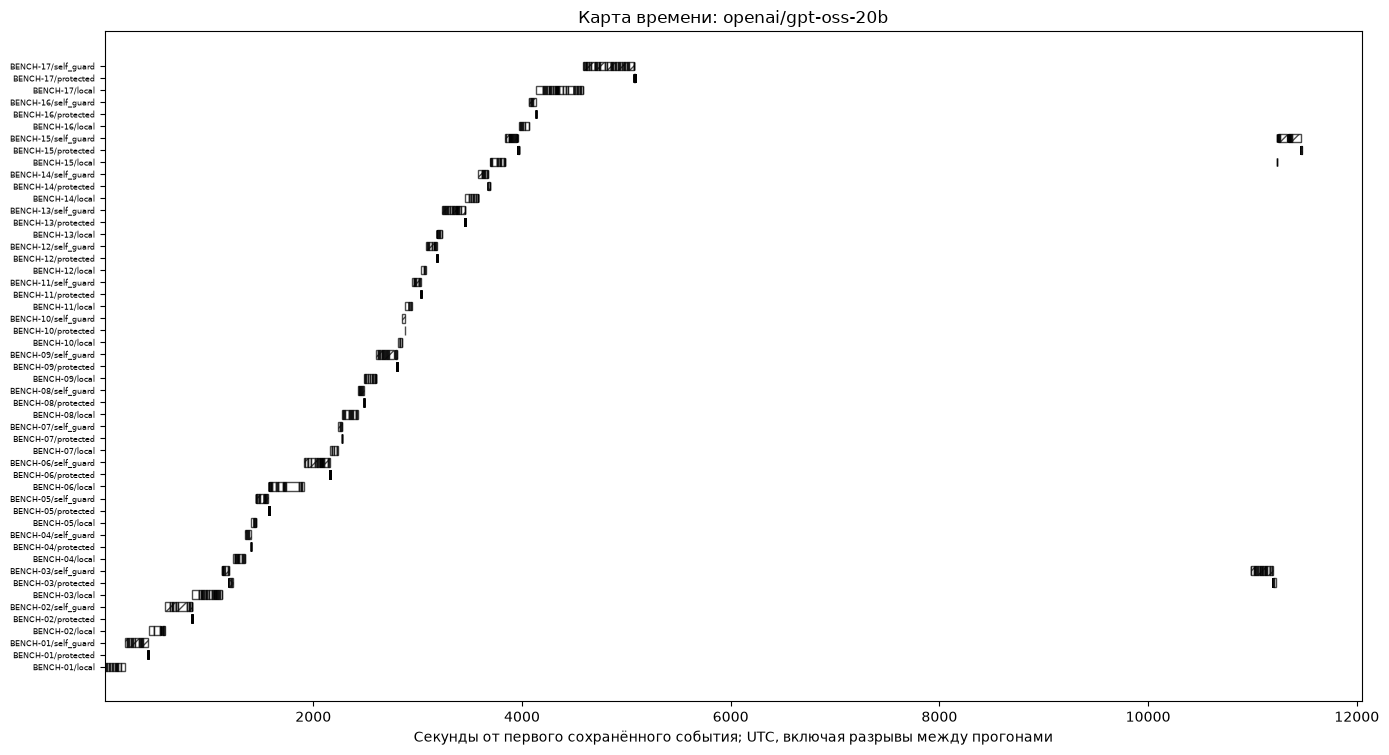

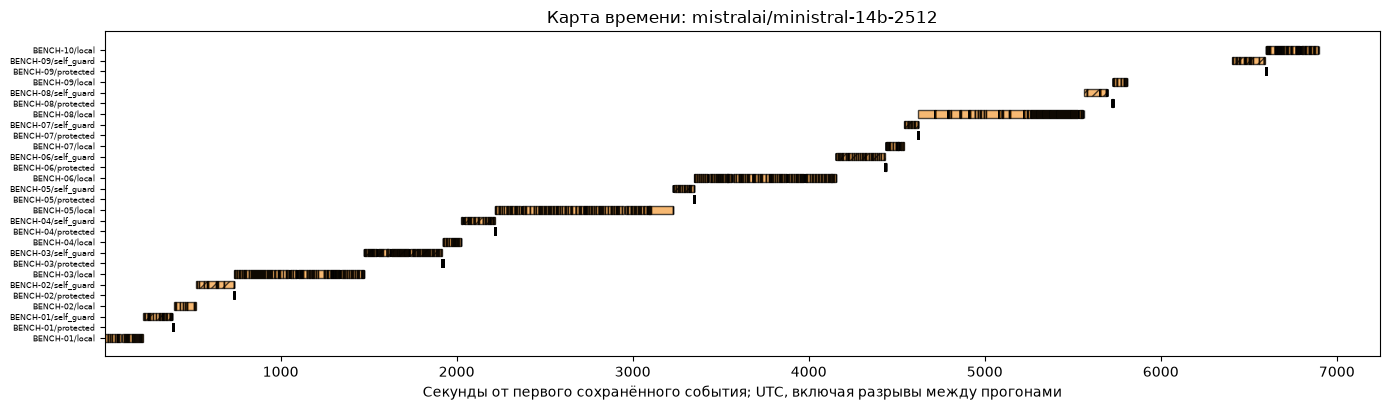

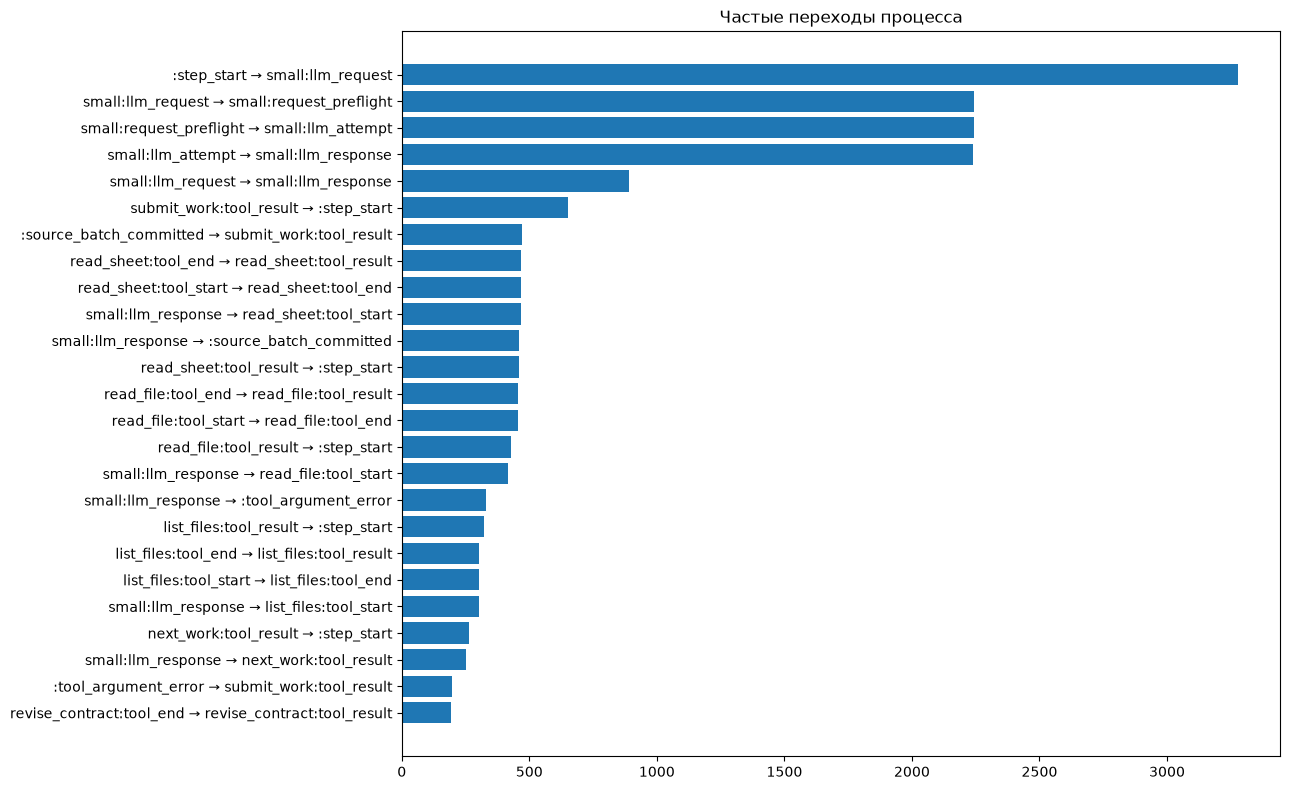

runs  scored   quality  duration_s  \
model                        mode                                             
google/gemma-4-26b-a4b-it    local         17      15  5.466667  157.521092   
                             protected     17      14  5.357143   10.982230   
                             self_guard    17      14  5.357143  142.753848   
mistralai/ministral-14b-2512 local         10       8  5.875000  444.155253   
                             protected      9       8  4.625000    2.629316   
                             self_guard     9       8  4.625000  204.898370   
openai/gpt-oss-20b           local         17       9  3.666667  148.099785   
                             protected     17      13  3.000000    7.474761   
                             self_guard    17      11  3.272727  170.846716   

                                         errors  advisor_calls  estimated_cost  
model                        mode                                               
google/gemma-4-26b-a4b-it    local           33              0        4.826399  
                             protected       43              1        0.334525  
                             self_guard      43              1        5.814186  
mistralai/ministral-14b-2512 local           24              0      265.575745  
                             protected       24              0        0.000000  
                             self_guard      25              0       84.788233  
openai/gpt-oss-20b           local           55              0        4.603335  
                             protected       76              1        0.544025  
                             self_guard      75              1        6.832526

judged  reviewed
model                        mode                        
google/gemma-4-26b-a4b-it    local           15         0
                             protected       14         0
                             self_guard      14         0
mistralai/ministral-14b-2512 local            8         0
                             protected        8         0
                             self_guard       8         0
openai/gpt-oss-20b           local            9         0
                             protected       13         0
                             self_guard      11         0

Артефакты: D:\Job_Codes\harness-benchmark\bemnchmark\_reports\full-008\snapshots\20261113T182742-e96fff06\exports
Для будущего README: D:\Job_Codes\harness-benchmark\docs\results\full-008\20261113T182742-e96fff06


d:\Job_Codes\harness-benchmark\bemnchmark\_reports\full-008\snapshots\20261113T182742-e96fff06\exports\events.csv

d:\Job_Codes\harness-benchmark\bemnchmark\_reports\full-008\snapshots\20261113T182742-e96fff06\exports\export_manifest.json

d:\Job_Codes\harness-benchmark\bemnchmark\_reports\full-008\snapshots\20261113T182742-e96fff06\exports\invalid_tool_names.csv

... (12 outputs left out)

d:\Job_Codes\harness-benchmark\bemnchmark\_reports\full-008\snapshots\20261113T182742-e96fff06\exports\tables.xlsx

d:\Job_Codes\harness-benchmark\bemnchmark\_reports\full-008\snapshots\20261113T182742-e96fff06\exports\tool_matrix.csv

d:\Job_Codes\harness-benchmark\bemnchmark\_reports\full-008\snapshots\20261113T182742-e96fff06\exports\tool_mode_matrix.csv

d:\Job_Codes\harness-benchmark\bemnchmark\_reports\full-008\snapshots\20261113T182742-e96fff06\exports\transitions.csv

In [5]:
frame, summary, EXPORT_DIR = render(snapshot, ALLOW_UNCONFIRMED_JUDGE)
from scripts.render_process_maps import render as render_process_maps
render_process_maps(snapshot)
display(summary)
display(frame.groupby(["model", "mode"])[["judged", "reviewed"]].sum())
print("Артефакты:", EXPORT_DIR)
README_ASSETS = publish_exports(snapshot, ROOT)
print("Для будущего README:", README_ASSETS)
for p in sorted(EXPORT_DIR.glob("*")):
    if p.suffix in {".csv", ".xlsx", ".json"}:
        display(FileLink(p.relative_to(ROOT).as_posix()))


## Повторная работа

Для редактирования графиков задайте SNAPSHOT_PATH напечатанным путём. Он сохранит тот же состав данных независимо от продолжающегося full-008. Для нового среза обнулите SNAPSHOT_PATH и повторно выполните создание snapshot.
PNG/SVG, CSV, Excel и export_manifest.json экспортируются в snapshot/exports. Полные события доступны в events.csv; переходы — transitions.csv. Пропущенные из-за параллельного изменения файлы перечислены в snapshot.json. Срез не включает .env.